# 3. Selección de modelo con validación cruzada (RF2, RF4, RNF4)
**RetailNova — Caso 1 (SCY1102 Gestión de Proyectos de Datos, Sección 001D)** · Hurtubia · Pacheco · Curi · Gómez

Se comparan **Regresión Logística** (interpretable) y **Random Forest** (más flexible) con validación cruzada de 5 folds estratificados **solo sobre el conjunto de entrenamiento**. Código en `src/modelado.py`.

## 3.1 Configuración y partición

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar src/ desde notebooks/

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as cfg

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

Partición estratificada 80/20 (semilla 42). El conjunto de prueba no se toca hasta el cuaderno 04. Variables: 12 numéricas + `canal_compra` (one-hot); `recencia_dias` queda fuera por fuga de datos.

In [2]:
from src.modelado import (dividir_datos, comparar_modelos_cv, elegir_modelo, modelos_candidatos,
                          construir_preprocesador, validacion_cruzada, seleccionar_umbral_oof)
df = pd.read_csv(cfg.CSV_PREPARADO)
X_train, X_test, y_train, y_test, reg_train, reg_test = dividir_datos(df)
assert cfg.VARIABLE_FUGA not in X_train.columns
print("Entrenamiento:", X_train.shape, "· prueba:", X_test.shape)
print("Predictoras:", list(X_train.columns))

Entrenamiento: (41076, 13) · prueba: (10270, 13)
Predictoras: ['edad', 'cantidad_compras', 'frecuencia_compra', 'monto_promedio_compra', 'monto_total_acumulado', 'uso_promociones', 'devoluciones', 'reclamos', 'interacciones_marketing', 'antiguedad_dias', 'tasa_reclamos', 'tasa_devoluciones', 'canal_compra']


## 3.2 Validación cruzada (5 folds)

In [3]:
folds, comparacion = comparar_modelos_cv(X_train, y_train)
comparacion

,Modelo,ROC_AUC_CV,ROC_AUC_std,F1_CV_0.5,Recall_CV_0.5
0,Random Forest,0.909,0.002,0.691,0.876
1,Regresión Logística,0.908,0.002,0.697,0.847


In [4]:
folds.round(4)

,Modelo,Fold,ROC_AUC,F1_umbral_0.5,Recall_umbral_0.5
0,Regresión Logística,1,0.910,0.699,0.840
1,Regresión Logística,2,0.907,0.695,0.848
2,Regresión Logística,3,0.910,0.692,0.850
3,Regresión Logística,4,0.907,0.703,0.848
4,Regresión Logística,5,0.906,0.695,0.851
5,Random Forest,1,0.912,0.686,0.869
6,Random Forest,2,0.907,0.692,0.873
7,Random Forest,3,0.910,0.694,0.884
8,Random Forest,4,0.911,0.698,0.880
9,Random Forest,5,0.906,0.684,0.873


## 3.3 Elección del modelo
Regla fijada **antes** de ver el conjunto de prueba: gana el mejor AUC de validación cruzada; si la diferencia con el otro modelo es menor a 0,01, se prefiere la **Regresión Logística** por simplicidad y explicabilidad (RNF4).

In [5]:
nombre = elegir_modelo(comparacion)
print("Modelo elegido:", nombre)
dif = comparacion.iloc[0]["ROC_AUC_CV"] - comparacion.iloc[1]["ROC_AUC_CV"]
print(f"Diferencia de AUC entre 1º y 2º: {dif:.4f} (umbral de empate: {cfg.DIFERENCIA_AUC_EMPATE})")

Modelo elegido: Regresión Logística
Diferencia de AUC entre 1º y 2º: 0.0010 (umbral de empate: 0.01)


## 3.4 Umbral de decisión con predicciones fuera de muestra (OOF)
Un modelo puede ordenar bien (AUC alto) y aun así detectar pocos abandonos con el umbral por defecto (0,5). Para cumplir la meta del plan (recall ≥ 70 %) se elige el umbral con predicciones OOF del entrenamiento: **el más alto con recall OOF ≥ 0,75** (margen de seguridad sobre la meta).

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, recall_score, precision_score

pipe = Pipeline([("prep", construir_preprocesador()), ("modelo", modelos_candidatos()[nombre])])
proba_oof = cross_val_predict(pipe, X_train, y_train, cv=validacion_cruzada(), method="predict_proba")[:, 1]
umbral = seleccionar_umbral_oof(proba_oof, y_train)
pred_oof = proba_oof >= umbral
print(f"Umbral OOF = {umbral:.4f}")
print(f"Recall OOF = {recall_score(y_train, pred_oof):.3f} · Precisión OOF = {precision_score(y_train, pred_oof):.3f}")

Umbral OOF = 0.6415
Recall OOF = 0.750 · Precisión OOF = 0.651


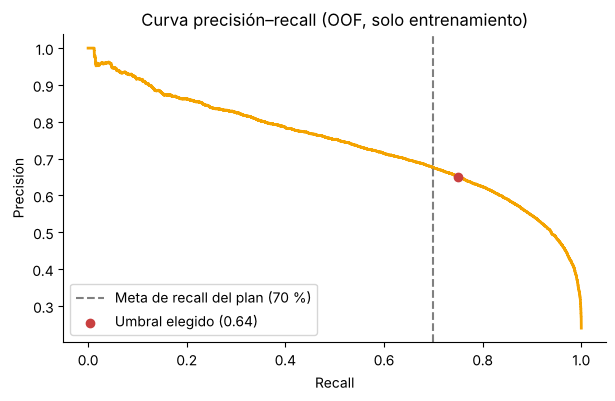

In [7]:
precision, recall, _ = precision_recall_curve(y_train, proba_oof)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recall, precision, color="#F4A300", lw=2)
ax.axvline(cfg.META_RECALL, ls="--", color="gray", label="Meta de recall del plan (70 %)")
ax.scatter([recall_score(y_train, pred_oof)], [precision_score(y_train, pred_oof)], color="#C94040", zorder=3, label=f"Umbral elegido ({umbral:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precisión"); ax.set_title("Curva precisión–recall (OOF, solo entrenamiento)"); ax.legend()
plt.show()

## 3.5 Ajuste final y guardado
La función `entrenar` repite este flujo, ajusta el modelo con todo el entrenamiento y guarda modelo, comparación y selección (lo usan los cuadernos 04–06).

In [8]:
from src.modelado import entrenar
seleccion = entrenar(df)
seleccion

             Modelo  ROC_AUC_CV  ROC_AUC_std  F1_CV_0.5  Recall_CV_0.5
      Random Forest       0.909        0.002      0.691          0.876
Regresión Logística       0.908        0.002      0.697          0.847

Modelo elegido ANTES de tocar el conjunto de prueba: Regresión Logística


Umbral OOF = 0.6415 · recall OOF 0.750 · precisión OOF 0.651


{'modelo': 'Regresión Logística',
 'umbral_decision': 0.641514988628949,
 'recall_oof': 0.7500507202272266,
 'precision_oof': 0.6514537444933921,
 'auc_cv': {'Random Forest': [0.9092022674531866, 0.0023245476211563977],
  'Regresión Logística': [0.9081750391649918, 0.0018144262558737574]},
 'n_entrenamiento': 41076}

**Siguiente:** `04_evaluacion_y_equidad.ipynb`.